#**Практическое задание №1**

Установка необходимых пакетов:

In [1]:
!pip install -q tqdm
!pip install --upgrade --no-cache-dir gdown

  Attempting uninstall: gdown
    Found existing installation: gdown 5.2.2
    Uninstalling gdown-5.2.2:
      Successfully uninstalled gdown-5.2.2


Монтирование Вашего Google Drive к текущему окружению:

In [2]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


Константы, которые пригодятся в коде далее, и ссылки (gdrive идентификаторы) на предоставляемые наборы данных:

In [3]:
EVALUATE_ONLY = False
TEST_ON_LARGE_DATASET = True
TISSUE_CLASSES = ('ADI', 'BACK', 'DEB', 'LYM', 'MUC', 'MUS', 'NORM', 'STR', 'TUM')
DATASETS_LINKS = {
    'train': '1XtQzVQ5XbrfxpLHJuL0XBGJ5U7CS-cLi',
    'train_small': '1qd45xXfDwdZjktLFwQb-et-mAaFeCzOR',
    'train_tiny': '1I-2ZOuXLd4QwhZQQltp817Kn3J0Xgbui',
    'test': '1RfPou3pFKpuHDJZ-D9XDFzgvwpUBFlDr',
    'test_small': '1wbRsog0n7uGlHIPGLhyN-PMeT2kdQ2lI',
    'test_tiny': '1viiB0s041CNsAK4itvX8PnYthJ-MDnQc'
}

In [4]:
WEIGHTS_URL = '1DlGINneW2YjrqvIdbNGSimXJvgp6LSjH'

Импорт необходимых зависимостей:

In [5]:
%matplotlib inline

from pathlib import Path
import json
import urllib.request
import numpy as np
from typing import List
from tqdm.auto import tqdm
from time import sleep
from PIL import Image
import IPython.display
import matplotlib.pyplot as plt
from sklearn.metrics import balanced_accuracy_score, confusion_matrix, classification_report
from sklearn.model_selection import train_test_split
import gdown

import torch
import torch.nn as nn
from torchvision import models, transforms as T

CHECKPOINT_DIR = Path('checkpoints')
RESULTS_DIR = Path('results')

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

---
### Класс Dataset

Предназначен для работы с наборами данных, обеспечивает чтение изображений и соответствующих меток, а также формирование пакетов (батчей).

In [6]:
class Dataset:

    def __init__(self, name):
        self.name = name
        self.is_loaded = False
        output = f'{name}.npz'
        if not Path(output).exists():
            url = f"https://drive.google.com/uc?export=download&confirm=pbef&id={DATASETS_LINKS[name]}"
            gdown.download(url, output, quiet=False)
        print(f'Loading dataset {self.name} from npz.')
        np_obj = np.load(output)
        self.images = np_obj['data']
        self.labels = np_obj['labels']
        self.n_files = self.images.shape[0]
        self.is_loaded = True
        print(f'Done. Dataset {name} consists of {self.n_files} images.')

    def image(self, i):
        # read i-th image in dataset and return it as numpy array
        if self.is_loaded:
            return self.images[i, :, :, :]

    def images_seq(self, n=None):
        # sequential access to images inside dataset (is needed for testing)
        for i in range(self.n_files if not n else n):
            yield self.image(i)

    def random_image_with_label(self):
        # get random image with label from dataset
        i = np.random.randint(self.n_files)
        return self.image(i), self.labels[i]

    def random_batch_with_labels(self, n):
        # create random batch of images with labels (is needed for training)
        indices = np.random.choice(self.n_files, n)
        imgs = [self.image(i) for i in indices]
        labels = np.array([self.labels[i] for i in indices])
        return np.stack(imgs), labels

    def image_with_label(self, i: int):
        # return i-th image with label from dataset
        return self.image(i), self.labels[i]


### Пример использвания класса Dataset
Загрузим обучающий набор данных, получим произвольное изображение с меткой. После чего визуализируем изображение, выведем метку. В будущем, этот кусок кода можно закомментировать или убрать.

Downloading...
From (original): https://drive.google.com/uc?id=1I-2ZOuXLd4QwhZQQltp817Kn3J0Xgbui
From (redirected): https://drive.google.com/uc?id=1I-2ZOuXLd4QwhZQQltp817Kn3J0Xgbui&confirm=t&uuid=d24139ae-a3c4-480e-bf82-51e71233b433
To: /content/train_tiny.npz
100%|██████████| 105M/105M [00:02<00:00, 41.7MB/s] 


Loading dataset train_tiny from npz.
Done. Dataset train_tiny consists of 900 images.

Got numpy array of shape (224, 224, 3), and label with code 5.
Label code corresponds to MUS class.


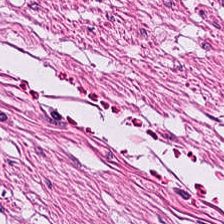

In [7]:
d_train_tiny = Dataset('train_tiny')

img, lbl = d_train_tiny.random_image_with_label()
print()
print(f'Got numpy array of shape {img.shape}, and label with code {lbl}.')
print(f'Label code corresponds to {TISSUE_CLASSES[lbl]} class.')

pil_img = Image.fromarray(img)
IPython.display.display(pil_img)

### Обёртка над Dataset для использования с PyTorch

In [8]:
# ============================================================
# (Опционально) Обёртка над Dataset для использования с PyTorch
# ============================================================

# ВНИМАНИЕ:
# Этот код нужен только тем, кто хочет решать задание с помощью PyTorch.
# Он показывает, как "подключить" наш Dataset к torch.utils.data.DataLoader.

try:
    import torch
    from torch.utils.data import Dataset as TorchDataset, DataLoader
    import torchvision.transforms as T
    from PIL import Image

    class HistologyTorchDataset(TorchDataset):
        """
        Обёртка над Dataset для использования с PyTorch.

        base_dataset: экземпляр Dataset('train'), Dataset('train_small'), etc.
        transform:    функция/объект, преобразующий изображение (PIL.Image -> torch.Tensor).
        """

        def __init__(self, base_dataset, transform=None):
            self.base = base_dataset
            # Минимальный transform по умолчанию:
            # np.uint8 [0, 255] -> float32 [0.0, 1.0]
            self.transform = transform or T.ToTensor()

        def __len__(self):
            # Размер датасета
            return len(self.base.images)

        def __getitem__(self, idx):
            """
            Возвращает (image_tensor, label) для PyTorch.
            image_tensor: torch.Tensor формы [3, H, W]
            label: int
            """
            img, label = self.base.image_with_label(idx)  # img: np.ndarray (H, W, 3)
            img = Image.fromarray(img)                    # в PIL.Image
            img = self.transform(img)                     # в torch.Tensor
            return img, int(label)

except ImportError:
    HistologyTorchDataset = None
    print("PyTorch / torchvision не найдены. Обёртка HistologyTorchDataset недоступна.")


### Пример использвания класса HistologyTorchDataset

In [9]:
if "HistologyTorchDataset" not in globals() or HistologyTorchDataset is None:
    print("PyTorch не установлен или обёртка недоступна — пример пропущен.")
else:
    print("Пример использования PyTorch-обёртки над Dataset")

    base_train = Dataset('train_tiny')

    # Создаём PyTorch-совместимый датасет
    train_ds = HistologyTorchDataset(base_train)

    # DataLoader автоматически создаёт батчи и перемешивает данные
    from torch.utils.data import DataLoader
    train_loader = DataLoader(train_ds, batch_size=8, shuffle=True)

    # Берём один батч и выводим информацию
    images_batch, labels_batch = next(iter(train_loader))

    print("Форма батча изображений:", tuple(images_batch.shape))  # [batch, 3, 224, 224]
    print("Форма батча меток:", tuple(labels_batch.shape))        # [batch]
    print("Пример меток:", labels_batch[:10].tolist())

    print("Тип images_batch:", type(images_batch))
    print("Тип labels_batch:", type(labels_batch))


Пример использования PyTorch-обёртки над Dataset
Loading dataset train_tiny from npz.
Done. Dataset train_tiny consists of 900 images.
Форма батча изображений: (8, 3, 224, 224)
Форма батча меток: (8,)
Пример меток: [4, 8, 6, 0, 0, 1, 5, 0]
Тип images_batch: <class 'torch.Tensor'>
Тип labels_batch: <class 'torch.Tensor'>


---
### Класс Metrics

Реализует метрики точности, используемые для оценивания модели:
1. точность,
2. сбалансированную точность.

In [10]:
class Metrics:

    @staticmethod
    def accuracy(gt: List[int], pred: List[int]):
        assert len(gt) == len(pred), 'gt and prediction should be of equal length'
        return sum(int(i[0] == i[1]) for i in zip(gt, pred)) / len(gt)

    @staticmethod
    def accuracy_balanced(gt: List[int], pred: List[int]):
        return balanced_accuracy_score(gt, pred)

    @staticmethod
    def print_all(gt: List[int], pred: List[int], info: str):
        print(f'metrics for {info}:')
        print('\t accuracy {:.4f}:'.format(Metrics.accuracy(gt, pred)))
        print('\t balanced accuracy {:.4f}:'.format(Metrics.accuracy_balanced(gt, pred)))

---
### Класс Model

Класс, хранящий в себе всю информацию о модели.

Вам необходимо реализовать методы save, load для сохранения и загрузки модели. Особенно актуально это будет во время тестирования на дополнительных наборах данных.


> *Пожалуйста, убедитесь, что сохранение и загрузка модели работает корректно. Для этого обучите модель, протестируйте, сохраните ее в файл, перезапустите среду выполнения, загрузите обученную модель из файла, вновь протестируйте ее на тестовой выборке и убедитесь в том, что получаемые метрики совпадают с полученными для тестовой выборки ранее.*


Также, Вы можете реализовать дополнительные функции, такие как:
1. валидацию модели на части обучающей выборки;
2. использование кроссвалидации;
3. автоматическое сохранение модели при обучении;
4. загрузку модели с какой-то конкретной итерации обучения (если используется итеративное обучение);
5. вывод различных показателей в процессе обучения (например, значение функции потерь на каждой эпохе);
6. построение графиков, визуализирующих процесс обучения (например, график зависимости функции потерь от номера эпохи обучения);
7. автоматическое тестирование на тестовом наборе/наборах данных после каждой эпохи обучения (при использовании итеративного обучения);
8. автоматический выбор гиперпараметров модели во время обучения;
9. сохранение и визуализацию результатов тестирования;
10. Использование аугментации и других способов синтетического расширения набора данных (дополнительным плюсом будет обоснование необходимости и обоснование выбора конкретных типов аугментации)
11. и т.д.

Полный список опций и дополнений приведен в презентации с описанием задания.

При реализации дополнительных функций допускается добавление параметров в существующие методы и добавление новых методов в класс модели.


In [11]:
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

#LBL11
TRAIN_TF = T.Compose([
    T.RandomHorizontalFlip(),
    T.RandomVerticalFlip(),
    T.RandomRotation(90),
    T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.05),
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
EVAL_TF = T.Compose([
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])


def _view(images, labels):
    class View:
        def __init__(self, images, labels):
            self.images = images
            self.labels = np.asarray(labels)

        def image_with_label(self, i):
            return self.images[i], int(self.labels[i])

    return View(images, labels)


class Model:

    def __init__(self, pretrained=True):
        self.device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        weights = models.MobileNet_V3_Small_Weights.DEFAULT if pretrained else None
        self.net = models.mobilenet_v3_small(weights=weights)
        in_features = self.net.classifier[-1].in_features
        self.net.classifier[-1] = nn.Linear(in_features, len(TISSUE_CLASSES))
        self.net.to(self.device)
        self.history = {
            'train_loss': [], 'val_loss': [],
            'train_acc': [], 'val_acc': [],
            'test_acc': [], 'test_bacc': [],
        }
        self.best_val_acc = -1.0
        self.best_epoch = 0
        self.last_epoch = 0
        self.optimizer = None
        self._opt_to_load = None

    def _ckpt(self):
        return {
            'model_state': self.net.state_dict(),
            'optimizer_state': None if self.optimizer is None else self.optimizer.state_dict(),
            'history': self.history,
            'best_val_acc': self.best_val_acc,
            'best_epoch': self.best_epoch,
            'last_epoch': self.last_epoch,
        }

    def save(self, name: str):
        payload = self._ckpt()
        path = CHECKPOINT_DIR / f'{name}.pt'
        torch.save(payload, path)
        torch.save(payload, f'{name}.pt')
        print(f'сохранил {path} и {name}.pt, эпоха {self.last_epoch}')

    def _apply_ckpt(self, ckpt):
        self.net.load_state_dict(ckpt['model_state'])
        self.history = ckpt.get('history', self.history)
        self.best_val_acc = float(ckpt.get('best_val_acc', -1.0))
        self.best_epoch = int(ckpt.get('best_epoch', ckpt.get('epoch', 0)))
        self.last_epoch = int(ckpt.get('last_epoch', ckpt.get('epoch', 0)))
        self._opt_to_load = ckpt.get('optimizer_state')
        self.net.to(self.device)
        self.net.eval()

    def load(self, name: str):
        name_to_id_dict = {
            'best': WEIGHTS_URL,
        }
        file_id = name_to_id_dict.get(name)
        if not file_id:
            raise FileNotFoundError('WEIGHTS_URL пустой')
        output = f'{name}.pt'
        file_id = str(file_id)
        if file_id.startswith('http') and 'drive.google.com' not in file_id:
            urllib.request.urlretrieve(file_id, output)
            print('скачал', file_id, '->', output, 'байт', Path(output).stat().st_size)
        elif file_id.startswith('http'):
            gdown.download(file_id, output, quiet=False)
        else:
            gdown.download(id=file_id, output=output, quiet=False)
            print('скачал id', file_id, 'байт', Path(output).stat().st_size)
        ckpt = torch.load(output, map_location=self.device, weights_only=False)
        self._apply_ckpt(ckpt)
        print(f'load({name}): веса с эпохи {self.best_epoch}, best_val_acc {self.best_val_acc:.4f}')

    #LBL4
    def load_epoch(self, epoch: int):
        path = CHECKPOINT_DIR / f'epoch_{epoch:03d}.pt'
        ckpt = torch.load(path, map_location=self.device, weights_only=False)
        self._apply_ckpt(ckpt)
        print(f'load_epoch({epoch}) из {path}, last_epoch={self.last_epoch}')

    def _predict_indices(self, dataset, indices):
        indices = np.asarray(indices)
        view = _view(dataset.images[indices], np.asarray(dataset.labels)[indices])
        loader = torch.utils.data.DataLoader(
            HistologyTorchDataset(view, transform=EVAL_TF),
            batch_size=64, shuffle=False, num_workers=0,
        )
        preds = []
        self.net.eval()
        with torch.no_grad():
            for x, _ in loader:
                preds.extend(self.net(x.to(self.device)).argmax(1).cpu().tolist())
        return preds

    def test_on_dataset(self, dataset, limit=None, indices=None):
        if indices is None:
            n = dataset.n_files if not limit else int(dataset.n_files * limit)
            indices = np.arange(n)
        return self._predict_indices(dataset, indices)

    def test_on_image(self, img, submission_year=2026):
        self.net.eval()
        x = EVAL_TF(Image.fromarray(img)).unsqueeze(0).to(self.device)
        with torch.no_grad():
            return int(self.net(x).argmax(1).item())

    def plot_history(self):
        #LBL6
        if not self.history['train_loss']:
            print('history пустой')
            return
        epochs = range(1, len(self.history['train_loss']) + 1)
        fig, axes = plt.subplots(1, 2, figsize=(10, 4))
        axes[0].plot(epochs, self.history['train_loss'], label='train')
        axes[0].plot(epochs, self.history['val_loss'], label='val')
        axes[0].set_title('loss')
        axes[0].set_xlabel('epoch')
        axes[0].legend()
        axes[1].plot(epochs, self.history['train_acc'], label='train')
        axes[1].plot(epochs, self.history['val_acc'], label='val')
        if any(v is not None for v in self.history['test_acc']):
            axes[1].plot(epochs, self.history['test_acc'], label='test')
        axes[1].set_title('accuracy')
        axes[1].set_xlabel('epoch')
        axes[1].legend()
        fig.tight_layout()
        out = RESULTS_DIR / 'training_curves.png'
        fig.savefig(out, dpi=120)
        plt.show()
        print('график', out)

    def train(self, dataset, test_dataset=None, epochs_head=3, epochs_ft=8,
              batch_size=32, lr_head=1e-3, lr_ft=3e-4, val_ratio=0.15,
              seed=42, resume=False, freeze_first=True, autosave=True,
              ckpt_dir=None):
        print('training started')
        print(
            f'device={self.device} freeze_first={freeze_first} '
            f'epochs_head={epochs_head} epochs_ft={epochs_ft} '
            f'lr_head={lr_head} lr_ft={lr_ft} resume={resume}'
        )
        ckpt_dir = Path(ckpt_dir) if ckpt_dir else CHECKPOINT_DIR
        ckpt_dir.mkdir(parents=True, exist_ok=True)
        np.random.seed(seed)
        torch.manual_seed(seed)

        #LBL12
        if resume:
            path = Path(ckpt_dir) / 'last.pt'
            ckpt = torch.load(path, map_location=self.device, weights_only=False)
            self._apply_ckpt(ckpt)
            n_state = 0 if not self._opt_to_load else len(self._opt_to_load.get('state', {}))
            print(f'resume с эпохи {self.last_epoch}, state оптимизатора: {n_state} тензоров')

        labels = np.asarray(dataset.labels)
        idx = np.arange(len(labels))
        #LBL1
        train_idx, val_idx = train_test_split(
            idx, test_size=val_ratio, random_state=seed, stratify=labels
        )
        generator = torch.Generator()
        generator.manual_seed(seed)
        train_loader = torch.utils.data.DataLoader(
            HistologyTorchDataset(_view(dataset.images[train_idx], labels[train_idx]), transform=TRAIN_TF),
            batch_size=batch_size, shuffle=True, num_workers=0, generator=generator,
        )
        val_loader = torch.utils.data.DataLoader(
            HistologyTorchDataset(_view(dataset.images[val_idx], labels[val_idx]), transform=EVAL_TF),
            batch_size=batch_size, shuffle=False, num_workers=0,
        )
        test_loader = None
        if test_dataset is not None:
            test_loader = torch.utils.data.DataLoader(
                HistologyTorchDataset(test_dataset, transform=EVAL_TF),
                batch_size=64, shuffle=False, num_workers=0,
            )
        print(f'train {len(train_idx)}  val {len(val_idx)}')

        def eval_loader(loader):
            self.net.eval()
            criterion = nn.CrossEntropyLoss()
            total_loss, preds, gts = 0.0, [], []
            with torch.no_grad():
                for x, y in loader:
                    x = x.to(self.device)
                    y = y.to(self.device)
                    logits = self.net(x)
                    total_loss += criterion(logits, y).item() * x.size(0)
                    preds.extend(logits.argmax(1).cpu().tolist())
                    gts.extend(y.cpu().tolist())
            n = max(len(gts), 1)
            acc = sum(int(a == b) for a, b in zip(gts, preds)) / n
            bacc = float(balanced_accuracy_score(gts, preds))
            return total_loss / n, acc, bacc

        def run_phase(n_epochs, lr, freeze_backbone, phase):
            if n_epochs <= 0:
                return
            for p in self.net.features.parameters():
                p.requires_grad = not freeze_backbone
            params = [p for p in self.net.parameters() if p.requires_grad]
            self.optimizer = torch.optim.Adam(params, lr=lr)
            if self._opt_to_load is not None:
                self.optimizer.load_state_dict(self._opt_to_load)
                self._opt_to_load = None
                for group in self.optimizer.param_groups:
                    group['lr'] = lr
                moments = [s['exp_avg'].abs().mean().item() for s in self.optimizer.state.values() if 'exp_avg' in s]
                mean_m = float(np.mean(moments)) if moments else 0.0
                print(f'{phase}: Adam взят из чекпоинта, средний |exp_avg|={mean_m:.3e}, lr снова {lr}')
            scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(self.optimizer, T_max=n_epochs)
            criterion = nn.CrossEntropyLoss()
            for _ in range(n_epochs):
                self.last_epoch += 1
                self.net.train()
                running, correct, total = 0.0, 0, 0
                for x, y in tqdm(train_loader, desc=f'{phase} ep {self.last_epoch}'):
                    x = x.to(self.device)
                    y = y.to(self.device)
                    self.optimizer.zero_grad()
                    logits = self.net(x)
                    loss = criterion(logits, y)
                    loss.backward()
                    self.optimizer.step()
                    running += loss.item() * x.size(0)
                    correct += int((logits.argmax(1) == y).sum().item())
                    total += x.size(0)
                current_lr = self.optimizer.param_groups[0]['lr']
                scheduler.step()
                train_loss = running / max(total, 1)
                train_acc = correct / max(total, 1)
                val_loss, val_acc, _ = eval_loader(val_loader)
                test_acc = test_bacc = None
                #LBL5
                msg = (
                    f'[{phase}] epoch {self.last_epoch}: lr={current_lr:.6f} '
                    f'train_loss={train_loss:.4f} train_acc={train_acc:.4f} '
                    f'val_loss={val_loss:.4f} val_acc={val_acc:.4f}'
                )
                if test_loader is not None:
                    #LBL7
                    _, test_acc, test_bacc = eval_loader(test_loader)
                    msg += f' test_acc={test_acc:.4f} test_bacc={test_bacc:.4f}'
                print(msg)
                self.history['train_loss'].append(train_loss)
                self.history['val_loss'].append(val_loss)
                self.history['train_acc'].append(train_acc)
                self.history['val_acc'].append(val_acc)
                self.history['test_acc'].append(test_acc)
                self.history['test_bacc'].append(test_bacc)
                if val_acc > self.best_val_acc:
                    self.best_val_acc = val_acc
                    self.best_epoch = self.last_epoch
                    improved = True
                else:
                    improved = False
                if autosave:
                    #LBL3
                    payload = self._ckpt()
                    payload['epoch'] = self.last_epoch
                    payload['val_acc'] = val_acc
                    payload['test_acc'] = test_acc
                    torch.save(payload, ckpt_dir / f'epoch_{self.last_epoch:03d}.pt')
                    torch.save(payload, ckpt_dir / 'last.pt')
                    if improved and ckpt_dir == CHECKPOINT_DIR:
                        torch.save(payload, ckpt_dir / 'best.pt')
                        torch.save(payload, 'best.pt')
                        print(f'  best обновлён, val_acc={val_acc:.4f}')
                    elif improved:
                        torch.save(payload, ckpt_dir / 'best.pt')
                        print(f'  best в {ckpt_dir.name} обновлён, val_acc={val_acc:.4f}')

        #LBL13
        if freeze_first:
            run_phase(epochs_head, lr_head, True, 'head')
            self._opt_to_load = None
            run_phase(epochs_ft, lr_ft, False, 'finetune')
        else:
            run_phase(epochs_ft, lr_ft, False, 'all')
            self._opt_to_load = None
            run_phase(epochs_head, lr_head, True, 'head')

        if autosave and (ckpt_dir / 'best.pt').exists() and ckpt_dir == CHECKPOINT_DIR:
            best = torch.load(ckpt_dir / 'best.pt', map_location=self.device, weights_only=False)
            self.net.load_state_dict(best['model_state'])
            self.best_val_acc = float(best['best_val_acc'])
            self.best_epoch = int(best.get('best_epoch', best['last_epoch']))
            print(f'вернул лучшие веса, эпоха {self.best_epoch}, val_acc={self.best_val_acc:.4f}')
        print('training done')


---
### Классификация изображений

Используя введенные выше классы можем перейти уже непосредственно к обучению модели классификации изображений. Пример общего пайплайна решения задачи приведен ниже. Вы можете его расширять и улучшать. В данном примере используются наборы данных 'train_small' и 'test_small'.

Сначала на `train_tiny`.

Вся сеть с lr=0.1 за одну эпоху. Потом две эпохи только головы против двух эпох сразу всей сети, оба раза lr=1e-3.


In [12]:
bad = Model()
bad.train(
    d_train_tiny,
    epochs_head=0,
    epochs_ft=1,
    lr_ft=0.1,
    freeze_first=False,
    autosave=False,
    seed=1,
)
print('lr=0.1, val_acc:', round(bad.best_val_acc, 4))


Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 191MB/s]


training started
device=cuda freeze_first=False epochs_head=0 epochs_ft=1 lr_head=0.001 lr_ft=0.1 resume=False
train 765  val 135


all ep 1:   0%|          | 0/24 [00:00<?, ?it/s]

[all] epoch 1: lr=0.100000 train_loss=150.5603 train_acc=0.1098 val_loss=2948630521119205.5000 val_acc=0.1111
training done
lr=0.1, val_acc: 0.1111


In [13]:
head_only = Model()
head_only.train(
    d_train_tiny,
    epochs_head=2,
    epochs_ft=0,
    lr_head=1e-3,
    freeze_first=True,
    autosave=False,
    seed=1,
)
all_layers = Model()
all_layers.train(
    d_train_tiny,
    epochs_head=0,
    epochs_ft=2,
    lr_ft=1e-3,
    freeze_first=False,
    autosave=False,
    seed=1,
)
print('только голова, val_acc:', round(head_only.best_val_acc, 4))
print('сразу вся сеть, val_acc:', round(all_layers.best_val_acc, 4))


training started
device=cuda freeze_first=True epochs_head=2 epochs_ft=0 lr_head=0.001 lr_ft=0.0003 resume=False
train 765  val 135


head ep 1:   0%|          | 0/24 [00:00<?, ?it/s]

[head] epoch 1: lr=0.001000 train_loss=1.2520 train_acc=0.5882 val_loss=1.2183 val_acc=0.5704


head ep 2:   0%|          | 0/24 [00:00<?, ?it/s]

[head] epoch 2: lr=0.000500 train_loss=0.6824 train_acc=0.7804 val_loss=0.8912 val_acc=0.7037
training done
training started
device=cuda freeze_first=False epochs_head=0 epochs_ft=2 lr_head=0.001 lr_ft=0.001 resume=False
train 765  val 135


all ep 1:   0%|          | 0/24 [00:00<?, ?it/s]

[all] epoch 1: lr=0.001000 train_loss=0.9912 train_acc=0.6863 val_loss=1.0434 val_acc=0.6519


all ep 2:   0%|          | 0/24 [00:00<?, ?it/s]

[all] epoch 2: lr=0.000500 train_loss=0.3783 train_acc=0.8667 val_loss=0.8459 val_acc=0.7333
training done
только голова, val_acc: 0.7037
сразу вся сеть, val_acc: 0.7333


In [14]:
d_train = Dataset('train_small')
d_test = Dataset('test')


Downloading...
From (original): https://drive.google.com/uc?id=1qd45xXfDwdZjktLFwQb-et-mAaFeCzOR
From (redirected): https://drive.google.com/uc?id=1qd45xXfDwdZjktLFwQb-et-mAaFeCzOR&confirm=t&uuid=2b82ffdc-d5d3-44d3-822d-647ca6075541
To: /content/train_small.npz
100%|██████████| 841M/841M [00:20<00:00, 40.4MB/s]


Loading dataset train_small from npz.
Done. Dataset train_small consists of 7200 images.


Downloading...
From (original): https://drive.google.com/uc?id=1RfPou3pFKpuHDJZ-D9XDFzgvwpUBFlDr
From (redirected): https://drive.google.com/uc?id=1RfPou3pFKpuHDJZ-D9XDFzgvwpUBFlDr&confirm=t&uuid=81be945d-19cb-4285-8937-e0771e0a8bcf
To: /content/test.npz
100%|██████████| 525M/525M [00:08<00:00, 61.7MB/s]


Loading dataset test from npz.
Done. Dataset test consists of 4500 images.


training started
device=cuda freeze_first=True epochs_head=3 epochs_ft=8 lr_head=0.001 lr_ft=0.0003 resume=False
train 6120  val 1080


head ep 1:   0%|          | 0/192 [00:00<?, ?it/s]

[head] epoch 1: lr=0.001000 train_loss=0.6160 train_acc=0.7923 val_loss=0.3159 val_acc=0.9102 test_acc=0.8873 test_bacc=0.8873
  best обновлён, val_acc=0.9102


head ep 2:   0%|          | 0/192 [00:00<?, ?it/s]

[head] epoch 2: lr=0.000750 train_loss=0.4162 train_acc=0.8636 val_loss=0.2762 val_acc=0.9130 test_acc=0.9036 test_bacc=0.9036
  best обновлён, val_acc=0.9130


head ep 3:   0%|          | 0/192 [00:00<?, ?it/s]

... (13 outputs left out)

finetune ep 10:   0%|          | 0/192 [00:00<?, ?it/s]

[finetune] epoch 10: lr=0.000044 train_loss=0.0678 train_acc=0.9775 val_loss=0.0792 val_acc=0.9750 test_acc=0.9764 test_bacc=0.9764
  best обновлён, val_acc=0.9750


finetune ep 11:   0%|          | 0/192 [00:00<?, ?it/s]

[finetune] epoch 11: lr=0.000011 train_loss=0.0679 train_acc=0.9776 val_loss=0.0788 val_acc=0.9769 test_acc=0.9764 test_bacc=0.9764
  best обновлён, val_acc=0.9769
вернул лучшие веса, эпоха 11, val_acc=0.9769
training done
сохранил checkpoints/best.pt и best.pt, эпоха 11


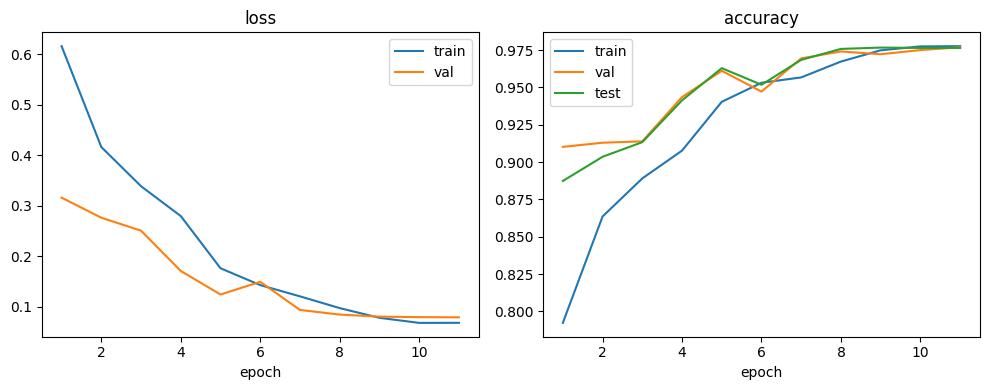

график results/training_curves.png


In [15]:
model = Model()
if not EVALUATE_ONLY:
    # 3 эпохи только голова, потом 8 эпох вся сеть
    model.train(
        d_train,
        d_test,
        epochs_head=3,
        epochs_ft=8,
        lr_head=1e-3,
        lr_ft=3e-4,
    )
    model.save('best')
    model.plot_history()
else:
    model.load('best')
    model.plot_history()


Пример тестирования модели на части набора данных:

In [16]:
rng = np.random.RandomState(0)
parts = []
labels_np = np.asarray(d_test.labels)
for c in range(len(TISSUE_CLASSES)):
    pool = np.flatnonzero(labels_np == c)
    take = max(1, int(round(0.1 * len(pool))))
    parts.append(rng.choice(pool, size=take, replace=False))
idx10 = np.concatenate(parts)
pred_1 = model.test_on_dataset(d_test, indices=idx10)
Metrics.print_all(labels_np[idx10].tolist(), pred_1, '10% of test, по классам')
print('классов в этом куске:', len(set(labels_np[idx10].tolist())))


metrics for 10% of test, по классам:
	 accuracy 0.9822:
	 balanced accuracy 0.9822:
классов в этом куске: 9


Пример тестирования модели на полном наборе данных:

In [17]:
# evaluating model on full test dataset (may take time)
if TEST_ON_LARGE_DATASET:
    pred_2 = model.test_on_dataset(d_test)
    Metrics.print_all(list(map(int, d_test.labels)), pred_2, 'test')


metrics for test:
	 accuracy 0.9764:
	 balanced accuracy 0.9764:


Результат работы пайплайна обучения и тестирования выше тоже будет оцениваться. Поэтому не забудьте присылать на проверку ноутбук с выполнеными ячейками кода с демонстрациями метрик обучения, графиками и т.п. В этом пайплайне Вам необходимо продемонстрировать работу всех реализованных дополнений, улучшений и т.п.

<font color="red">
Настоятельно рекомендуется после получения пайплайна с полными результатами обучения экспортировать ноутбук в pdf (файл -> печать) и прислать этот pdf вместе с самим ноутбуком.
</font>

### Тестирование модели на других наборах данных

Ваша модель должна поддерживать тестирование на других наборах данных. Для удобства, Вам предоставляется набор данных test_tiny, который представляет собой малую часть (2% изображений) набора test. Ниже приведен фрагмент кода, который будет осуществлять тестирование для оценивания Вашей модели на дополнительных тестовых наборах данных.

<font color="red">
Прежде чем отсылать задание на проверку, убедитесь в работоспособности фрагмента кода ниже.
</font>


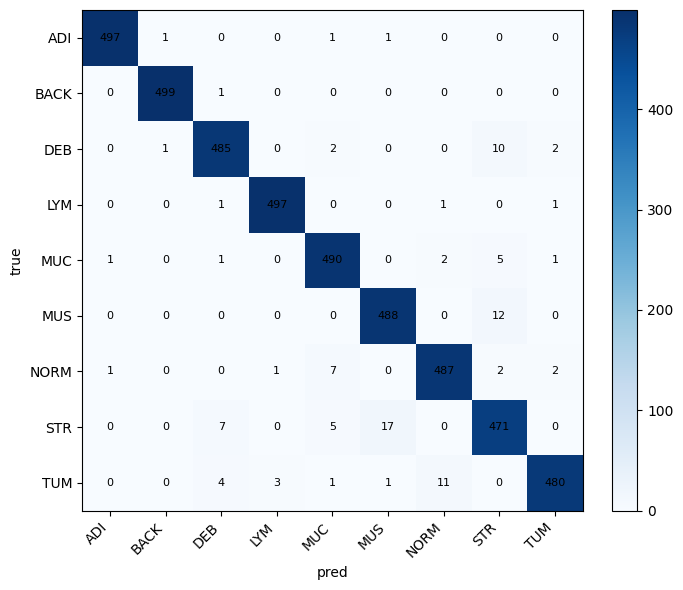

sensitivity / specificity
  ADI: sens=0.994 spec=1.000
  BACK: sens=0.998 spec=1.000
  DEB: sens=0.970 spec=0.997
  LYM: sens=0.994 spec=0.999
  MUC: sens=0.980 spec=0.996
  MUS: sens=0.976 spec=0.995
  NORM: sens=0.974 spec=0.997
  STR: sens=0.942 spec=0.993
  TUM: sens=0.960 spec=0.999
STR чаще всего уезжает в MUS (17), DEB (7), MUC (5)
              precision    recall  f1-score   support

         ADI     0.9960    0.9940    0.9950       500
        BACK     0.9960    0.9980    0.9970       500
         DEB     0.9719    0.9700    0.9710       500
         LYM     0.9920    0.9940    0.9930       500
         MUC     0.9684    0.9800    0.9742       500
         MUS     0.9625    0.9760    0.9692       500
        NORM     0.9721    0.9740    0.9730       500
         STR     0.9420    0.9420    0.9420       500
         TUM     0.9877    0.9600    0.9736       500

    accuracy                         0.9764      4500
   macro avg     0.9765    0.9764    0.9764      4500
weighted 

In [18]:
#LBL8
#LBL10
gt = list(map(int, d_test.labels))
cm = confusion_matrix(gt, pred_2, labels=list(range(len(TISSUE_CLASSES))))
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(len(TISSUE_CLASSES)))
ax.set_yticks(range(len(TISSUE_CLASSES)))
ax.set_xticklabels(TISSUE_CLASSES, rotation=45, ha='right')
ax.set_yticklabels(TISSUE_CLASSES)
ax.set_xlabel('pred')
ax.set_ylabel('true')
for i in range(len(TISSUE_CLASSES)):
    for j in range(len(TISSUE_CLASSES)):
        ax.text(j, i, str(cm[i, j]), ha='center', va='center', fontsize=8)
fig.colorbar(im, ax=ax, fraction=0.046)
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'confusion_test.png', dpi=120)
plt.show()

total = cm.sum()
print('sensitivity / specificity')
for i, name in enumerate(TISSUE_CLASSES):
    tp = cm[i, i]
    fn = cm[i].sum() - tp
    fp = cm[:, i].sum() - tp
    tn = total - tp - fn - fp
    sens = tp / (tp + fn) if tp + fn else 0
    spec = tn / (tn + fp) if tn + fp else 0
    print(f'  {name}: sens={sens:.3f} spec={spec:.3f}')

str_i = TISSUE_CLASSES.index('STR')
pairs = [(int(cm[str_i, j]), TISSUE_CLASSES[j]) for j in range(len(TISSUE_CLASSES)) if j != str_i]
pairs.sort(reverse=True)
print('STR чаще всего уезжает в', ', '.join(f'{name} ({n})' for n, name in pairs[:3]))
print(classification_report(gt, pred_2, target_names=TISSUE_CLASSES, digits=4))
with open(RESULTS_DIR / 'metrics_test.json', 'w') as f:
    json.dump({
        'accuracy': Metrics.accuracy(gt, pred_2),
        'balanced_accuracy': float(Metrics.accuracy_balanced(gt, pred_2)),
        'str_confused_with': [{'class': name, 'n': n} for n, name in pairs[:3]],
    }, f, indent=2, ensure_ascii=False)


Чекпоинт ранней эпохи против лучших весов, на test_tiny. Это `load_epoch`.


In [19]:
#LBL4
early = Model()
early.load_epoch(4)
d_test_tiny_early = Dataset('test_tiny')
pred_early = early.test_on_dataset(d_test_tiny_early)
pred_best_tiny = model.test_on_dataset(d_test_tiny_early)
yt = list(map(int, d_test_tiny_early.labels))
Metrics.print_all(yt, pred_early, 'epoch 4, test_tiny')
Metrics.print_all(yt, pred_best_tiny, 'best, test_tiny')


load_epoch(4) из checkpoints/epoch_004.pt, last_epoch=4


Downloading...
From: https://drive.google.com/uc?id=1viiB0s041CNsAK4itvX8PnYthJ-MDnQc
To: /content/test_tiny.npz
100%|██████████| 10.6M/10.6M [00:00<00:00, 24.1MB/s]


Loading dataset test_tiny from npz.
Done. Dataset test_tiny consists of 90 images.
metrics for epoch 4, test_tiny:
	 accuracy 0.9222:
	 balanced accuracy 0.9222:
metrics for best, test_tiny:
	 accuracy 0.9889:
	 balanced accuracy 0.9889:


Проверка resume на tiny, отдельно от основного прогона, чтобы не затереть best.pt. Одна эпоха, новый объект Model, ещё одна эпоха с тем же Adam.


In [20]:
#LBL12
resume_model = Model()
resume_model.train(
    d_train_tiny,
    epochs_head=1,
    epochs_ft=0,
    lr_head=1e-3,
    autosave=True,
    ckpt_dir='checkpoints/resume_demo',
    seed=2,
)
kept_epoch = resume_model.last_epoch
resume_model.train(
    d_train_tiny,
    epochs_head=1,
    epochs_ft=0,
    lr_head=1e-3,
    resume=True,
    autosave=True,
    ckpt_dir='checkpoints/resume_demo',
    seed=2,
)
print('было эпох', kept_epoch, 'стало', resume_model.last_epoch)


training started
device=cuda freeze_first=True epochs_head=1 epochs_ft=0 lr_head=0.001 lr_ft=0.0003 resume=False
train 765  val 135


head ep 1:   0%|          | 0/24 [00:00<?, ?it/s]

[head] epoch 1: lr=0.001000 train_loss=1.2088 train_acc=0.6065 val_loss=1.2418 val_acc=0.5926
  best в resume_demo обновлён, val_acc=0.5926
training done
training started
device=cuda freeze_first=True epochs_head=1 epochs_ft=0 lr_head=0.001 lr_ft=0.0003 resume=True
resume с эпохи 1, state оптимизатора: 4 тензоров
train 765  val 135
head: Adam взят из чекпоинта, средний |exp_avg|=3.451e-03, lr снова 0.001


head ep 2:   0%|          | 0/24 [00:00<?, ?it/s]

[head] epoch 2: lr=0.001000 train_loss=0.3584 train_acc=0.8993 val_loss=0.8989 val_acc=0.6667
  best в resume_demo обновлён, val_acc=0.6667
training done
было эпох 1 стало 2


In [22]:
final_model = Model()
final_model.load('best')
d_test_tiny = Dataset('test_tiny')
pred = final_model.test_on_dataset(d_test_tiny)
Metrics.print_all(d_test_tiny.labels, pred, 'test-tiny')

Downloading...
From: https://drive.google.com/uc?id=1DlGINneW2YjrqvIdbNGSimXJvgp6LSjH
To: /content/best.pt
100%|██████████| 18.5M/18.5M [00:00<00:00, 33.4MB/s]


скачал id 1DlGINneW2YjrqvIdbNGSimXJvgp6LSjH байт 18543639
load(best): веса с эпохи 10, best_val_acc 0.9750
Loading dataset test_tiny from npz.
Done. Dataset test_tiny consists of 90 images.
metrics for test-tiny:
	 accuracy 0.9778:
	 balanced accuracy 0.9778:


Google Drive пока не отключаем: примеры архивов ниже пишут файлы на Диск. Отключение стоит в последней ячейке.


In [23]:
# Диск остаётся примонтированным до последней ячейки.


---
# Дополнительные "полезности"

Ниже приведены примеры использования различных функций и библиотек, которые могут быть полезны при выполнении данного практического задания.

### Измерение времени работы кода

Измерять время работы какой-либо функции можно легко и непринужденно при помощи функции timeit из соответствующего модуля:

In [24]:
import timeit

def factorial(n):
    res = 1
    for i in range(1, n + 1):
        res *= i
    return res


def f():
    return factorial(n=1000)

n_runs = 128
print(f'Function f is caluclated {n_runs} times in {timeit.timeit(f, number=n_runs)}s.')

Function f is caluclated 128 times in 0.03162219799992272s.


### Scikit-learn

Для использования "классических" алгоритмов машинного обучения рекомендуется использовать библиотеку scikit-learn (https://scikit-learn.org/stable/). Пример классификации изображений цифр из набора данных MNIST при помощи классификатора SVM:

Classification report for classifier SVC(gamma=0.001):
              precision    recall  f1-score   support

           0       1.00      0.99      0.99        88
           1       0.99      0.97      0.98        91
           2       0.99      0.99      0.99        86
           3       0.98      0.87      0.92        91
           4       0.99      0.96      0.97        92
           5       0.95      0.97      0.96        91
           6       0.99      0.99      0.99        91
           7       0.96      0.99      0.97        89
           8       0.94      1.00      0.97        88
           9       0.93      0.98      0.95        92

    accuracy                           0.97       899
   macro avg       0.97      0.97      0.97       899
weighted avg       0.97      0.97      0.97       899




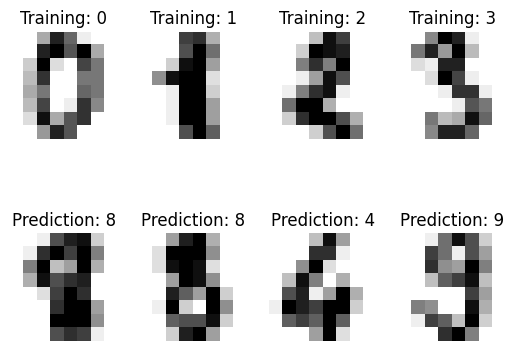

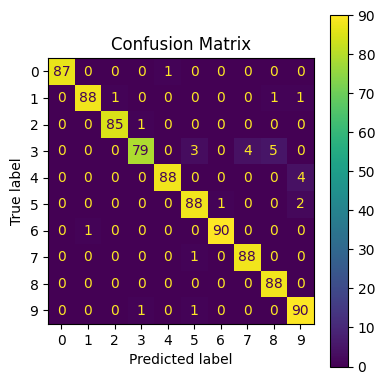

In [25]:
# Standard scientific Python imports
import matplotlib.pyplot as plt

# Import datasets, classifiers and performance metrics
from sklearn import datasets, svm, metrics
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split

# The digits dataset
digits = datasets.load_digits()

# The data that we are interested in is made of 8x8 images of digits, let's
# have a look at the first 4 images, stored in the `images` attribute of the
# dataset.  If we were working from image files, we could load them using
# matplotlib.pyplot.imread.  Note that each image must have the same size. For these
# images, we know which digit they represent: it is given in the 'target' of
# the dataset.
_, axes = plt.subplots(2, 4)
images_and_labels = list(zip(digits.images, digits.target))
for ax, (image, label) in zip(axes[0, :], images_and_labels[:4]):
    ax.set_axis_off()
    ax.imshow(image, cmap=plt.cm.gray_r, interpolation='nearest')
    ax.set_title('Training: %i' % label)

# To apply a classifier on this data, we need to flatten the image, to
# turn the data in a (samples, feature) matrix:
n_samples = len(digits.images)
data = digits.images.reshape((n_samples, -1))

# Create a classifier: a support vector classifier
classifier = svm.SVC(gamma=0.001)

# Split data into train and test subsets
X_train, X_test, y_train, y_test = train_test_split(
    data, digits.target, test_size=0.5, shuffle=False)

# We learn the digits on the first half of the digits
classifier.fit(X_train, y_train)

# Now predict the value of the digit on the second half:
predicted = classifier.predict(X_test)

images_and_predictions = list(zip(digits.images[n_samples // 2:], predicted))
for ax, (image, prediction) in zip(axes[1, :], images_and_predictions[:4]):
    ax.set_axis_off()
    ax.imshow(image, cmap=plt.cm.gray_r, interpolation='nearest')
    ax.set_title('Prediction: %i' % prediction)

print("Classification report for classifier %s:\n%s\n"
      % (classifier, metrics.classification_report(y_test, predicted)))

# Матрица ошибок + визуализация в новом API
cm = metrics.confusion_matrix(y_test, predicted)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=classifier.classes_)

fig, ax = plt.subplots(figsize=(4, 4))
disp.plot(ax=ax)
ax.set_title("Confusion Matrix")
plt.tight_layout()
plt.show()

### Scikit-image

Реализовывать различные операции для работы с изображениями можно как самостоятельно, работая с массивами numpy, так и используя специализированные библиотеки, например, scikit-image (https://scikit-image.org/). Ниже приведен пример использования Canny edge detector.

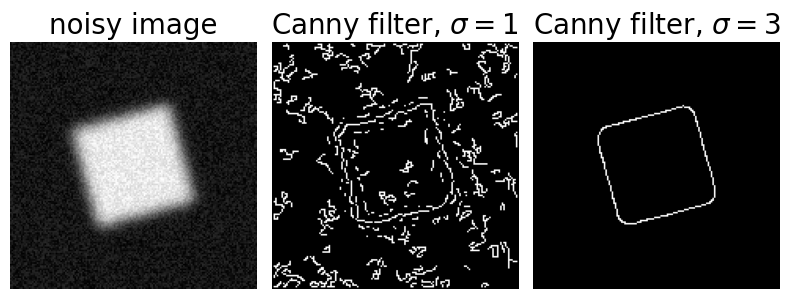

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage as ndi

from skimage import feature


# Generate noisy image of a square
im = np.zeros((128, 128))
im[32:-32, 32:-32] = 1

im = ndi.rotate(im, 15, mode='constant')
im = ndi.gaussian_filter(im, 4)
im += 0.2 * np.random.random(im.shape)

# Compute the Canny filter for two values of sigma
edges1 = feature.canny(im)
edges2 = feature.canny(im, sigma=3)

# display results
fig, (ax1, ax2, ax3) = plt.subplots(nrows=1, ncols=3, figsize=(8, 3),
                                    sharex=True, sharey=True)

ax1.imshow(im, cmap=plt.cm.gray)
ax1.axis('off')
ax1.set_title('noisy image', fontsize=20)

ax2.imshow(edges1, cmap=plt.cm.gray)
ax2.axis('off')
ax2.set_title(r'Canny filter, $\sigma=1$', fontsize=20)

ax3.imshow(edges2, cmap=plt.cm.gray)
ax3.axis('off')
ax3.set_title(r'Canny filter, $\sigma=3$', fontsize=20)

fig.tight_layout()

plt.show()

### Tensorflow 2

Для создания и обучения нейросетевых моделей можно использовать фреймворк глубокого обучения Tensorflow 2. Ниже приведен пример простейшей нейроной сети, использующейся для классификации изображений из набора данных MNIST.

In [27]:
# Install TensorFlow

import tensorflow as tf

mnist = tf.keras.datasets.mnist

(x_train, y_train), (x_test, y_test) = mnist.load_data()
x_train, x_test = x_train / 255.0, x_test / 255.0

demo_mnist_model = tf.keras.models.Sequential([
  tf.keras.layers.Flatten(input_shape=(28, 28)),
  tf.keras.layers.Dense(128, activation='relu'),
  tf.keras.layers.Dropout(0.2),
  tf.keras.layers.Dense(10, activation='softmax')
])

demo_mnist_model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

demo_mnist_model.fit(x_train, y_train, epochs=5)

demo_mnist_model.evaluate(x_test,  y_test, verbose=2)


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - accuracy: 0.9154 - loss: 0.2909
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9587 - loss: 0.1389
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9678 - loss: 0.1059
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9733 - loss: 0.0874
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9770 - loss: 0.0750
313/313 - 2s - 7ms/step - accuracy: 0.9774 - loss: 0.0735


[0.07354108989238739, 0.977400004863739]

<font color="red">
Для эффективной работы с моделями глубокого обучения убедитесь в том, что в текущей среде Google Colab используется аппаратный ускоритель GPU или TPU. Для смены среды выберите "среда выполнения" -> "сменить среду выполнения".
</font>

Большое количество туториалов и примеров с кодом на Tensorflow 2 можно найти на официальном сайте https://www.tensorflow.org/tutorials?hl=ru.

Также, Вам может понадобиться написать собственный генератор данных для Tensorflow 2. Скорее всего он будет достаточно простым, и его легко можно будет реализовать, используя официальную документацию TensorFlow 2. Но, на всякий случай (если не удлось сразу разобраться или хочется вникнуть в тему более глубоко), можете посмотреть следующий отличный туториал: https://stanford.edu/~shervine/blog/keras-how-to-generate-data-on-the-fly.

### PyTorch

Готовой сети и цикла обучения в шаблоне нет: это часть задания. Данные для PyTorch берёт класс `HistologyTorchDataset` выше. Ниже — ссылки на документацию.


In [28]:
print(
    "Для PyTorch используйте класс HistologyTorchDataset из ячеек выше. "
    "Ссылки на документацию — в следующей ячейке."
)


Для PyTorch используйте класс HistologyTorchDataset из ячеек выше. Ссылки на документацию — в следующей ячейке.


### Дополнительные ресурсы по PyTorch

- **Официальные туториалы PyTorch** — https://pytorch.org/tutorials/  
- **“Deep Learning with PyTorch: 60-Minute Blitz”** — https://pytorch.org/tutorials/beginner/deep_learning_60min_blitz.html  
- **Transfer Learning for Computer Vision** — https://pytorch.org/tutorials/beginner/transfer_learning_tutorial.html  
- **PyTorch Get Started (установка)** — https://pytorch.org/get-started/locally/  
- **Dive into Deep Learning (D2L, глава PyTorch)** — https://d2l.ai/chapter_preliminaries/index.html  
- **Fast.ai — Practical Deep Learning for Coders** — https://course.fast.ai/  
- **Learn PyTorch.io (Zero to Mastery)** — https://www.learnpytorch.io/

### Numba

В некоторых ситуациях, при ручных реализациях графовых алгоритмов, выполнение многократных вложенных циклов for в python можно существенно ускорить, используя JIT-компилятор Numba (https://numba.pydata.org/).
Примеры использования Numba в Google Colab можно найти тут:
1. https://colab.research.google.com/github/cbernet/maldives/blob/master/numba/numba_cuda.ipynb
2. https://colab.research.google.com/github/evaneschneider/parallel-programming/blob/master/COMPASS_gpu_intro.ipynb

> Пожалуйста, если Вы решили использовать Numba для решения этого практического задания, еще раз подумайте, нужно ли это Вам, и есть ли возможность реализовать требуемую функциональность иным способом. Используйте Numba только при реальной необходимости.



### Работа с zip архивами в Google Drive

Запаковка и распаковка zip архивов может пригодиться при сохранении и загрузки Вашей модели. Ниже приведен фрагмент кода, иллюстрирующий помещение нескольких файлов в zip архив с последующим чтением файлов из него. Все действия с директориями, файлами и архивами должны осущетвляться с примонтированным Google Drive.


Создадим 2 изображения, поместим их в директорию tmp внутри PROJECT_DIR, запакуем директорию tmp в архив tmp.zip.

In [29]:
PROJECT_DIR = "prak_nn_1"
arr1 = np.random.rand(100, 100, 3) * 255
arr2 = np.random.rand(100, 100, 3) * 255

img1 = Image.fromarray(arr1.astype('uint8'))
img2 = Image.fromarray(arr2.astype('uint8'))

p = str(Path("/content/drive/MyDrive") / PROJECT_DIR)
Path(p, "tmp").mkdir(parents=True, exist_ok=True)

img1.save(str(Path(p) / "tmp" / "img1.png"))
img2.save(str(Path(p) / "tmp" / "img2.png"))

%cd $p
!zip -r "tmp.zip" "tmp"


/content/drive/MyDrive/prak_nn_1
  adding: tmp/ (stored 0%)
  adding: tmp/img1.png (stored 0%)
  adding: tmp/img2.png (stored 0%)


Распакуем архив tmp.zip в директорию tmp2 в PROJECT_DIR. Теперь внутри директории tmp2 содержится директория tmp, внутри которой находятся 2 изображения.

In [30]:
p = str(Path("/content/drive/MyDrive") / PROJECT_DIR)
%cd $p
!unzip -uq "tmp.zip" -d "tmp2"
%cd /content


/content/drive/MyDrive/prak_nn_1
/content


Отмонтировать Google Drive.


In [31]:
drive.flush_and_unmount()
